# GUIDE Dataset — Standalone Logistic Regression Baseline

Target: `IncidentGrade` (TruePositive / BenignPositive / FalsePositive), 3-class classification.

Scope for this notebook:
- Train and evaluate **Logistic Regression only**, as a linear baseline alongside the existing LightGBM result.
- Reuse the exact same cleaned dataset, audited feature set, and train/validation split saved by the LightGBM notebook (`guide-lightgbm-baseline`), mounted here via `kernel_sources`.
- Row alignment and `(OrgId, IncidentId)` group non-overlap are explicitly re-verified rather than assumed.
- The official `GUIDE_Test.csv` is **not loaded** — it stays untouched for a later, unbiased final comparison across models.

In [1]:
import os, glob, time, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import (
    accuracy_score, f1_score, classification_report, confusion_matrix
)

warnings.filterwarnings('ignore', category=FutureWarning)
pd.set_option('display.max_columns', 100)
sns.set_theme(style='whitegrid')
RANDOM_STATE = 42

OUT_DIR = '/kaggle/working'
os.makedirs(OUT_DIR, exist_ok=True)

t0 = time.time()
def lap(msg):
    print(f'[{time.time() - t0:7.1f}s] {msg}')

## 1. Load data and reproduce the LightGBM notebook's cleaning

Only `GUIDE_Train.csv` is loaded. The exact same cleaning steps as the LightGBM notebook (drop duplicate rows, then drop rows with a missing target) are applied, in the same order, so this produces the identical row set (by `Id`) that `split_assignment.csv` was built from.

In [2]:
matches = glob.glob('/kaggle/input/**/GUIDE_Train.csv', recursive=True)
if not matches:
    raise FileNotFoundError('GUIDE_Train.csv not found under /kaggle/input')
DATA_DIR = os.path.dirname(matches[0])
lap(f'Using DATA_DIR = {DATA_DIR}')

TARGET = 'IncidentGrade'

df = pd.read_csv(f'{DATA_DIR}/GUIDE_Train.csv')
lap(f'Loaded raw train = {df.shape}')

df = df.drop_duplicates().reset_index(drop=True)
lap(f'After dropping duplicate rows: {df.shape}')

df = df.dropna(subset=[TARGET]).reset_index(drop=True)
lap(f'After dropping rows with missing target: {df.shape}')

assert df[TARGET].notna().all()
print('Class distribution:')
print(df[TARGET].value_counts())

[    0.5s] Using DATA_DIR = /kaggle/input/datasets/Microsoft/microsoft-security-incident-prediction
[   43.0s] Loaded raw train = (9516837, 45)
[   76.5s] After dropping duplicate rows: (9494278, 45)
[   80.5s] After dropping rows with missing target: (9442956, 45)
Class distribution:
IncidentGrade
BenignPositive    4110748
TruePositive      3302644
FalsePositive     2029564
Name: count, dtype: int64


## 2. Reuse the audited feature set from the LightGBM notebook

`preprocessing_info.json` (saved by `guide-lightgbm-baseline`, mounted here as a kernel source) records the leakage review already performed: identifiers/hashes excluded, `ActionGrouped`/`ActionGranular` excluded as remediation-action leakage, and `SuspicionLevel`/`LastVerdict` reviewed and kept under the documented assumption that they are automated, pre-triage detection outputs rather than a restatement of the final grade. That review is **not redone here** — it is loaded and reused as-is so the two models are compared on the same input information.

In [3]:
prep_matches = glob.glob('/kaggle/input/**/preprocessing_info.json', recursive=True)
if not prep_matches:
    raise FileNotFoundError('preprocessing_info.json not found under /kaggle/input — '
                            'check that kernel_sources includes guide-lightgbm-baseline')
with open(prep_matches[0]) as f:
    lgb_preprocessing_info = json.load(f)
lap(f'Loaded preprocessing_info.json from {prep_matches[0]}')

CATEGORICAL_COLS = lgb_preprocessing_info['categorical_cols']
NUMERIC_COLS = lgb_preprocessing_info['numeric_cols']
ID_LIKE_COLS = lgb_preprocessing_info['excluded_id_cols']
LEAKAGE_COLS = lgb_preprocessing_info['excluded_leakage_cols']
GROUP_COLS = lgb_preprocessing_info['group_cols']
FEATURES = CATEGORICAL_COLS + NUMERIC_COLS

print('Categorical features (reused):', len(CATEGORICAL_COLS), CATEGORICAL_COLS)
print('Numeric features (reused):', len(NUMERIC_COLS), NUMERIC_COLS)
print('Excluded as identifiers/hashes:', len(ID_LIKE_COLS))
print('Excluded as remediation-action leakage:', LEAKAGE_COLS)
print('Total reused features:', len(FEATURES))
assert set(FEATURES) == set(lgb_preprocessing_info['features']), 'Feature set mismatch vs LightGBM notebook!'

# Drop every raw column we will never use (24 high-cardinality identifier/hash columns,
# e.g. Sha256, Url, AccountSid, ...) now that dedup/target-cleaning already ran on the
# full column set. This happens *after* the cleaning in cell-3, so it does not change
# which rows survive (still identical to the LightGBM notebook's row set) — it only
# frees the memory those unused columns were holding before the heavier steps below.
DERIVED_COLS = ['Hour', 'DayOfWeek', 'MitreCount', 'MitrePrimary']
RAW_NEEDED_COLS = ['Id', 'OrgId', 'IncidentId', TARGET, 'Timestamp', 'MitreTechniques'] + \
    [c for c in FEATURES if c not in DERIVED_COLS]
before_cols = df.shape[1]
df = df[RAW_NEEDED_COLS].copy()
import gc
gc.collect()
lap(f'Dropped unused raw columns: {before_cols} -> {df.shape[1]} columns, {df.shape[0]} rows unchanged')

[   81.4s] Loaded preprocessing_info.json from /kaggle/input/notebooks/towsifhassan1132/guide-lightgbm-baseline/preprocessing_info.json
Categorical features (reused): 11 ['Category', 'EntityType', 'EvidenceRole', 'ResourceType', 'Roles', 'OSFamily', 'OSVersion', 'AntispamDirection', 'SuspicionLevel', 'LastVerdict', 'MitrePrimary']
Numeric features (reused): 8 ['DetectorId', 'AlertTitle', 'CountryCode', 'State', 'City', 'Hour', 'DayOfWeek', 'MitreCount']
Excluded as identifiers/hashes: 25
Excluded as remediation-action leakage: ['ActionGrouped', 'ActionGranular']
Total reused features: 19
[   84.0s] Dropped unused raw columns: 45 -> 21 columns, 9442956 rows unchanged


## 3. Feature engineering (identical to the LightGBM notebook)

`Timestamp` → `Hour`/`DayOfWeek`; `MitreTechniques` (semicolon-separated string) → count + primary technique. Same logic, same column names, so the engineered columns line up with `NUMERIC_COLS`/`CATEGORICAL_COLS` above.

In [4]:
df['Timestamp'] = pd.to_datetime(df['Timestamp'], errors='coerce')
df['Hour'] = df['Timestamp'].dt.hour
df['DayOfWeek'] = df['Timestamp'].dt.dayofweek

mitre = df['MitreTechniques'].fillna('')
df['MitreCount'] = mitre.apply(lambda s: 0 if s == '' else len(s.split(';')))
df['MitrePrimary'] = mitre.apply(lambda s: s.split(';')[0] if s != '' else 'None')

lap(f'Engineered features. Feature count: {len(FEATURES)}')

[   96.9s] Engineered features. Feature count: 19


## 4. Load and verify the saved train/validation split

`split_assignment.csv` (also mounted via `kernel_sources`) is merged onto `df` by `Id` — the split is **not recomputed**, it is reused exactly so this result is comparable to the LightGBM run. Row alignment (every row here has a split label, and counts match) and zero `(OrgId, IncidentId)` overlap between train and validation are both re-verified rather than assumed.

In [5]:
split_matches = glob.glob('/kaggle/input/**/split_assignment.csv', recursive=True)
if not split_matches:
    raise FileNotFoundError('split_assignment.csv not found under /kaggle/input — '
                            'check that kernel_sources includes guide-lightgbm-baseline')
split_assignment = pd.read_csv(split_matches[0], usecols=['Id', 'split'])
lap(f'Loaded split_assignment.csv from {split_matches[0]} ({len(split_assignment)} rows)')

# `Id` in this dataset is NOT a unique per-row key — it is shared by every row of the
# same incident (its nunique equals the LightGBM run's n_unique_groups, 707108), so
# split_assignment.csv has many repeated (Id, split) pairs. Every row sharing an Id
# was verified to share the same split value (checked separately), so deduplicating
# on Id before indexing is safe and gives the uniquely-valued index map() requires.
dup_check = split_assignment.drop_duplicates(subset=['Id'])
n_id_conflicts = split_assignment.groupby('Id')['split'].nunique().gt(1).sum()
assert n_id_conflicts == 0, f'{n_id_conflicts} Id values map to more than one split label!'
split_lookup = dup_check.set_index('Id')['split']
assert split_lookup.index.is_unique
del split_assignment, dup_check
gc.collect()

before_rows = len(df)
df['split'] = df['Id'].map(split_lookup)
del split_lookup
gc.collect()

n_missing_split = df['split'].isna().sum()
assert n_missing_split == 0, (
    f'Row alignment check FAILED: {n_missing_split} of {before_rows} cleaned rows got no split label. '
    'The cleaning in this notebook no longer matches the LightGBM notebook.'
)
assert len(df) == before_rows
assert df['split'].isin(['train', 'val']).all()
lap('Row alignment verified: every cleaned row received exactly one split label.')

group_key = df['OrgId'].astype(str) + '_' + df['IncidentId'].astype(str)
train_groups = set(group_key[df['split'] == 'train'])
val_groups = set(group_key[df['split'] == 'val'])
overlap = train_groups & val_groups
assert len(overlap) == 0, 'Group leakage between train and validation!'
lap(f'(OrgId, IncidentId) group overlap between train/val = {len(overlap)} (verified zero)')

print(df.groupby('split')[TARGET].value_counts())
print(f"Train rows: {(df['split']=='train').sum()}  Val rows: {(df['split']=='val').sum()}")

[   99.8s] Loaded split_assignment.csv from /kaggle/input/notebooks/towsifhassan1132/guide-lightgbm-baseline/split_assignment.csv (9442956 rows)
[  102.1s] Row alignment verified: every cleaned row received exactly one split label.
[  110.1s] (OrgId, IncidentId) group overlap between train/val = 0 (verified zero)
split  IncidentGrade 
train  BenignPositive    3288682
       TruePositive      2613852
       FalsePositive     1615837
val    BenignPositive     822066
       TruePositive       688792
       FalsePositive      413727
Name: count, dtype: int64
Train rows: 7518371  Val rows: 1924585


## 5. Logistic-regression-appropriate preprocessing

LightGBM used these numeric columns' raw integer codes directly because tree splits don't assume any linear/ordinal relationship. A linear model does, so `DetectorId`, `AlertTitle`, `CountryCode`, `State`, `City` are **encoded codes, not continuous quantities**, and are treated as categorical here instead — one-hot encoded like the true categorical columns. Only `Hour`, `DayOfWeek`, `MitreCount` are genuinely continuous/count-like and are scaled.

- All categorical-type columns (11 original categoricals + the 5 reclassified numeric-coded columns = 16) → missing values filled with an explicit `'Missing'` string, then one-hot encoded (`handle_unknown='ignore'`, rare categories below `min_frequency` bucketed into a single `infrequent` category, `max_categories` capped per column) to keep the sparse matrix width memory-efficient.
- The 3 remaining numeric columns → median-imputed, then standard-scaled.
- The whole transformer is fit **on the training split only**; the validation split is only ever `.transform()`-ed.
- The combined output is kept sparse (`scipy.sparse.csr_matrix`) throughout — never densified — since one-hot encoding ~7.5M rows across 16 columns would be far too large as a dense array.

**Comparability note:** the raw input columns are identical to the LightGBM run (same 19 audited features, same leakage exclusions). What differs is purely the *encoding* of 5 columns (one-hot instead of raw integer codes), which is a standard, expected adaptation for a linear model — not a change to the feature set. The `min_frequency`/`max_categories` bucketing of rare values is a linear-model-specific approximation with no LightGBM equivalent, so it is flagged as a limitation rather than silently applied.

In [6]:
ID_LIKE_NUMERIC_AS_CATEGORICAL = ['DetectorId', 'AlertTitle', 'CountryCode', 'State', 'City']
TRUE_NUMERIC_SCALE_COLS = [c for c in NUMERIC_COLS if c not in ID_LIKE_NUMERIC_AS_CATEGORICAL]
ONEHOT_COLS = CATEGORICAL_COLS + ID_LIKE_NUMERIC_AS_CATEGORICAL

assert set(ONEHOT_COLS + TRUE_NUMERIC_SCALE_COLS) == set(FEATURES)
print('One-hot (categorical + id-coded numeric) columns:', len(ONEHOT_COLS), ONEHOT_COLS)
print('Scaled true-numeric columns:', TRUE_NUMERIC_SCALE_COLS)

for col in ONEHOT_COLS:
    df[col] = df[col].fillna('Missing').astype(str)
for col in TRUE_NUMERIC_SCALE_COLS:
    df[col] = pd.to_numeric(df[col], errors='coerce')

target_classes = sorted(df[TARGET].unique())
target_map = {v: i for i, v in enumerate(target_classes)}
inv_target_map = {i: v for v, i in target_map.items()}
df['_target'] = df[TARGET].map(target_map)
print('Target classes:', target_map)

train_mask = df['split'] == 'train'
val_mask = df['split'] == 'val'
X_train_raw, y_train = df.loc[train_mask, FEATURES], df.loc[train_mask, '_target']
X_val_raw, y_val = df.loc[val_mask, FEATURES], df.loc[val_mask, '_target']
n_classes = len(target_map)
lap(f'X_train_raw={X_train_raw.shape}, X_val_raw={X_val_raw.shape}')

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(
            handle_unknown='ignore', min_frequency=1000, max_categories=100,
            sparse_output=True, dtype=np.float32
        ), ONEHOT_COLS),
        ('num', Pipeline(steps=[
            ('impute', SimpleImputer(strategy='median')),
            ('scale', StandardScaler()),
        ]), TRUE_NUMERIC_SCALE_COLS),
    ],
    sparse_threshold=1.0,
)

fit_start = time.time()
X_train = preprocessor.fit_transform(X_train_raw, y_train)
fit_time = time.time() - fit_start
X_val = preprocessor.transform(X_val_raw)
lap(f'Preprocessing fit on train in {fit_time:.1f}s. '
    f'X_train={X_train.shape} ({X_train.dtype}, sparse={hasattr(X_train, "nnz")}), X_val={X_val.shape}')

One-hot (categorical + id-coded numeric) columns: 16 ['Category', 'EntityType', 'EvidenceRole', 'ResourceType', 'Roles', 'OSFamily', 'OSVersion', 'AntispamDirection', 'SuspicionLevel', 'LastVerdict', 'MitrePrimary', 'DetectorId', 'AlertTitle', 'CountryCode', 'State', 'City']
Scaled true-numeric columns: ['Hour', 'DayOfWeek', 'MitreCount']
Target classes: {'BenignPositive': 0, 'FalsePositive': 1, 'TruePositive': 2}
[  138.8s] X_train_raw=(7518371, 19), X_val_raw=(1924585, 19)
[  241.0s] Preprocessing fit on train in 92.3s. X_train=(7518371, 539) (float64, sparse=True), X_val=(1924585, 539)


## 6. Train multiclass Logistic Regression

`solver='saga'` is used because it natively supports sparse input and multinomial (true multiclass, not one-vs-rest) loss at this scale, where batch solvers like `lbfgs` would be considerably slower on a ~7.5M-row sparse design matrix. `max_iter` is capped at a resource-conscious value; convergence is checked explicitly afterward rather than assumed.

In [7]:
model = LogisticRegression(
    solver='saga', penalty='l2', C=1.0,
    max_iter=100, tol=1e-3,
    random_state=RANDOM_STATE, verbose=0,
)

train_start = time.time()
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter('always', ConvergenceWarning)
    model.fit(X_train, y_train)
    convergence_warnings = [str(w.message) for w in caught if issubclass(w.category, ConvergenceWarning)]
training_time = time.time() - train_start

n_iter_run = int(np.max(model.n_iter_))
converged = n_iter_run < model.max_iter
lap(f'Training done in {training_time:.1f}s. n_iter_={model.n_iter_.tolist()}, '
    f'max_iter={model.max_iter}, converged={converged}')
if convergence_warnings:
    print('ConvergenceWarning(s) raised:')
    for w in convergence_warnings:
        print(' -', w)
else:
    print('No ConvergenceWarning raised.')

[ 1049.2s] Training done in 808.2s. n_iter_=[100], max_iter=100, converged=False
ConvergenceWarning(s) raised:
 - The max_iter was reached which means the coef_ did not converge


## 7. Evaluate on validation

                precision    recall  f1-score   support

BenignPositive       0.67      0.95      0.79    822066
 FalsePositive       0.83      0.42      0.56    413727
  TruePositive       0.84      0.67      0.75    688792

      accuracy                           0.74   1924585
     macro avg       0.78      0.68      0.70   1924585
  weighted avg       0.77      0.74      0.72   1924585

Accuracy: 0.7364  Macro-F1: 0.6964  Weighted-F1: 0.7227
Training time: 808.2s  (preprocessing fit time: 92.3s)


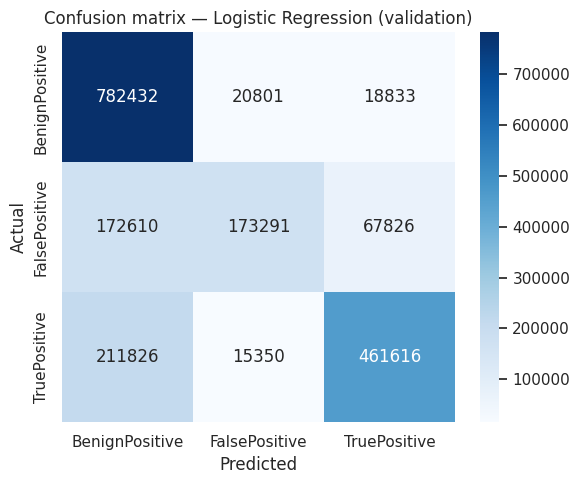

In [8]:
y_pred = model.predict(X_val)

accuracy = accuracy_score(y_val, y_pred)
macro_f1 = f1_score(y_val, y_pred, average='macro')
weighted_f1 = f1_score(y_val, y_pred, average='weighted')

labels_order = sorted(inv_target_map)
label_names = [inv_target_map[i] for i in labels_order]

report_dict = classification_report(
    y_val, y_pred, labels=labels_order, target_names=label_names, output_dict=True
)
print(classification_report(y_val, y_pred, labels=labels_order, target_names=label_names))
print(f'Accuracy: {accuracy:.4f}  Macro-F1: {macro_f1:.4f}  Weighted-F1: {weighted_f1:.4f}')
print(f'Training time: {training_time:.1f}s  (preprocessing fit time: {fit_time:.1f}s)')

cm = confusion_matrix(y_val, y_pred, labels=labels_order)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=label_names, yticklabels=label_names)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion matrix — Logistic Regression (validation)')
plt.tight_layout()
plt.savefig(f'{OUT_DIR}/confusion_matrix.png', dpi=120)
plt.show()

## 8. Save pipeline, results, and classification report

In [9]:
full_pipeline = Pipeline(steps=[('preprocessor', preprocessor), ('model', model)])
joblib.dump(full_pipeline, f'{OUT_DIR}/logreg_pipeline.pkl')

with open(f'{OUT_DIR}/classification_report.json', 'w') as f:
    json.dump(report_dict, f, indent=2)

preprocessing_info = {
    'features': FEATURES,
    'onehot_cols': ONEHOT_COLS,
    'scaled_numeric_cols': TRUE_NUMERIC_SCALE_COLS,
    'categorical_cols_from_lightgbm': CATEGORICAL_COLS,
    'numeric_cols_from_lightgbm': NUMERIC_COLS,
    'excluded_id_cols': ID_LIKE_COLS,
    'excluded_leakage_cols': LEAKAGE_COLS,
    'reviewed_kept_cols': ['SuspicionLevel', 'LastVerdict'],
    'group_cols': GROUP_COLS,
    'target_map': target_map,
    'onehot_min_frequency': 1000,
    'onehot_max_categories': 100,
    'reused_split_source': 'guide-lightgbm-baseline/split_assignment.csv',
    'reused_feature_audit_source': 'guide-lightgbm-baseline/preprocessing_info.json',
}
with open(f'{OUT_DIR}/preprocessing_info.json', 'w') as f:
    json.dump(preprocessing_info, f, indent=2)

results = {
    'dataset_rows_after_cleaning': int(len(df)),
    'train_rows': int(train_mask.sum()),
    'val_rows': int(val_mask.sum()),
    'n_features_raw': len(FEATURES),
    'n_features_encoded': int(X_train.shape[1]),
    'preprocessing_fit_time_seconds': round(fit_time, 1),
    'training_time_seconds': round(training_time, 1),
    'solver': 'saga',
    'max_iter': model.max_iter,
    'n_iter_': model.n_iter_.tolist(),
    'converged': bool(converged),
    'convergence_warnings': convergence_warnings,
    'accuracy': round(float(accuracy), 4),
    'macro_f1': round(float(macro_f1), 4),
    'weighted_f1': round(float(weighted_f1), 4),
    'per_class_report': report_dict,
    'confusion_matrix': cm.tolist(),
    'target_classes_order': label_names,
}
with open(f'{OUT_DIR}/results.json', 'w') as f:
    json.dump(results, f, indent=2)

lap('Saved logreg_pipeline.pkl, preprocessing_info.json, results.json, classification_report.json, confusion_matrix.png')
print(json.dumps({k: v for k, v in results.items() if k not in ('per_class_report', 'confusion_matrix')}, indent=2))

[ 1050.7s] Saved logreg_pipeline.pkl, preprocessing_info.json, results.json, classification_report.json, confusion_matrix.png
{
  "dataset_rows_after_cleaning": 9442956,
  "train_rows": 7518371,
  "val_rows": 1924585,
  "n_features_raw": 19,
  "n_features_encoded": 539,
  "preprocessing_fit_time_seconds": 92.3,
  "training_time_seconds": 808.2,
  "solver": "saga",
  "max_iter": 100,
  "n_iter_": [
    100
  ],
  "converged": false,
  "convergence_warnings": [
    "The max_iter was reached which means the coef_ did not converge"
  ],
  "accuracy": 0.7364,
  "macro_f1": 0.6964,
  "weighted_f1": 0.7227,
  "target_classes_order": [
    "BenignPositive",
    "FalsePositive",
    "TruePositive"
  ]
}


## 9. Summary & limitations

- Dataset, cleaning, leakage review, and train/validation split are all **reused exactly** from `guide-lightgbm-baseline` (verified: row counts match after merging the split, and `(OrgId, IncidentId)` group overlap between train/val is re-checked as zero here, not just assumed).
- Same 19 audited raw features as the LightGBM run. For this linear model, 5 numeric-but-really-categorical columns (`DetectorId`, `AlertTitle`, `CountryCode`, `State`, `City`) are one-hot encoded instead of used as raw integers, since a linear model would otherwise assume a false ordinal relationship between category codes.
- All preprocessing (one-hot encoding, imputation, scaling) is fit on the training split only and applied to validation via `.transform()`; the design matrix is kept sparse throughout.
- Limitation: `OneHotEncoder(min_frequency=1000, max_categories=100)` buckets rare category values into a shared "infrequent" bucket per column. This controls memory/time but means very rare category values lose their individual identity — a linear-model-specific approximation with no equivalent in the LightGBM run, so the two models are not using *identical* encoded information even though the raw input columns are the same.
- Limitation: `solver='saga'` with `max_iter=100` was chosen to keep training time bounded on ~7.5M rows; see the `converged`/`n_iter_` fields in `results.json` for whether the solver actually reached its stopping tolerance or was cut off at the iteration cap.
- The official test set was not touched in this notebook.